# 04 — Multimodal Text & Image Fusion

Goal: Combine state-of-the-art text (TF-IDF + SVM, CamemBERT) and image models (ConvNeXt-Tiny) to maximise classification performance.

- **Image Model**: `ConvNeXt-Tiny` (Full Fine-Tuning + Smart Cropping from `notebooks/03_image_fineTuning/03_7_image_convnext_optimized.ipynb`), reaching **0.6998 Weighted F1** alone.
- **Text Models**: Calibrated `LinearSVC` (**0.8430 Weighted F1**) and fine-tuned `CamemBERT` (**0.8765 Weighted F1**).
- **Fusion by soft voting**: average the probabilities of the models.
  1. **Equal weights** on CamemBERT, SVM and image: the final model. Nothing is fitted on the validation products.
  2. **Weighted soft voting**: weights chosen by cross-validation (SVM + image, CamemBERT + image, CamemBERT + SVM + image), for comparison only.
- **Tried and not kept** (section 5): a Random Forest that learns how to combine the probabilities.


## 1. Text probabilities

We use the optimised text model from notebook 03_2 (all features, binary TF-IDF, LinearSVC with C = 1). A LinearSVC gives scores, not probabilities. Calibration learns on the training set (3-fold CV) how to turn these scores into probabilities.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC

# Resolve repository root directory
PROJECT_ROOT             = Path.cwd().resolve()
while PROJECT_ROOT.name in {"notebooks"}:
    PROJECT_ROOT         = PROJECT_ROOT.parent

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

DATA_PATH                = PROJECT_ROOT / "data" / "processed" / "text_train_processed.csv"
TEXT_PROBS_OUT           = PROJECT_ROOT / "data" / "processed" / "text_validation_probabilities.csv"
IMAGE_PREDS_PATH         = PROJECT_ROOT / "models" / "outputs" / "03_7_convnext_tiny_optimized_validation_predictions.csv"
CAMEMBERT_PROBS_PATH     = PROJECT_ROOT / "data" / "processed" / "camembert_validation_probabilities.csv"

RANDOM_STATE             = 42
CV_FOLDS                 = 5

data                     = pd.read_csv(DATA_PATH)
train                    = data[data["split"] == "train"]
validation               = data[data["split"] == "validation"]

vectorizer               = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train                  = vectorizer.fit_transform(train["text_combined"])
X_validation             = vectorizer.transform(validation["text_combined"])

# Calibrated LinearSVC from notebook 03_2 (outputs well-calibrated class probabilities)
text_model               = CalibratedClassifierCV(LinearSVC(C=1, random_state=RANDOM_STATE), cv=3)
text_model.fit(X_train, train["prdtypecode"])
classes                  = text_model.classes_

text_probs               = pd.DataFrame(text_model.predict_proba(X_validation), columns=classes)
text_probs.insert(0, "row_id", validation["row_id"].to_numpy())
text_probs.to_csv(TEXT_PROBS_OUT, index=False)

print(f"Text probabilities saved: {text_probs.shape}")
print(f"Each row sums to 1      : {np.allclose(text_probs[classes].sum(axis=1), 1)}")


Text probabilities saved: (16984, 28)
Each row sums to 1      : True


## 2. Match text and image on the same products

In [2]:
# Best image model: ConvNeXt-Tiny (03_7_image_convnext_optimized)
image                    = pd.read_csv(IMAGE_PREDS_PATH)
image.columns            = [c.strip() for c in image.columns]
image_probs              = image[["row_id"] + [f"prob_{c}" for c in classes]]
image_probs.columns      = ["row_id"] + list(classes)

both                     = (
    validation[["row_id", "prdtypecode"]]
    .merge(text_probs,  on="row_id")
    .merge(image_probs, on="row_id", suffixes=("_text", "_image"))
)
y_true                   = both["prdtypecode"].to_numpy()
P_text                   = both[[f"{c}_text" for c in classes]].to_numpy()
P_image                  = both[[f"{c}_image" for c in classes]].to_numpy()

print(f"Products scored by both: {len(both):,}")


Products scored by both: 16,984


## 3. Combine the models

Text and image probabilities exist for the 16984 validation products, which none of the models were trained on.

Soft voting: average the probabilities of the models, then take the class with the highest average.
- Equal weights: each of the three models counts 1/3. Nothing is chosen, so it is scored directly on all 16984 products.
- Weighted soft voting: each model gets its own weight (steps of 0.1, summing to 1). The weights are chosen with 5-fold cross-validation: chosen on 4/5 of the products, applied to the remaining 1/5.


Weighted soft voting (SVM + image) — weights chosen in each fold: [(0.6, 0.4), (0.6, 0.4), (0.6, 0.4), (0.6, 0.4), (0.6, 0.4)]
Weighted soft voting (CamemBERT + image) — weights chosen in each fold: [(0.5, 0.5), (0.5, 0.5), (0.5, 0.5), (0.5, 0.5), (0.5, 0.5)]
Weighted soft voting (CamemBERT + SVM + image) — weights chosen in each fold: [(0.4, 0.3, 0.3), (0.4, 0.3, 0.3), (0.3, 0.4, 0.3), (0.4, 0.3, 0.3), (0.4, 0.3, 0.3)]


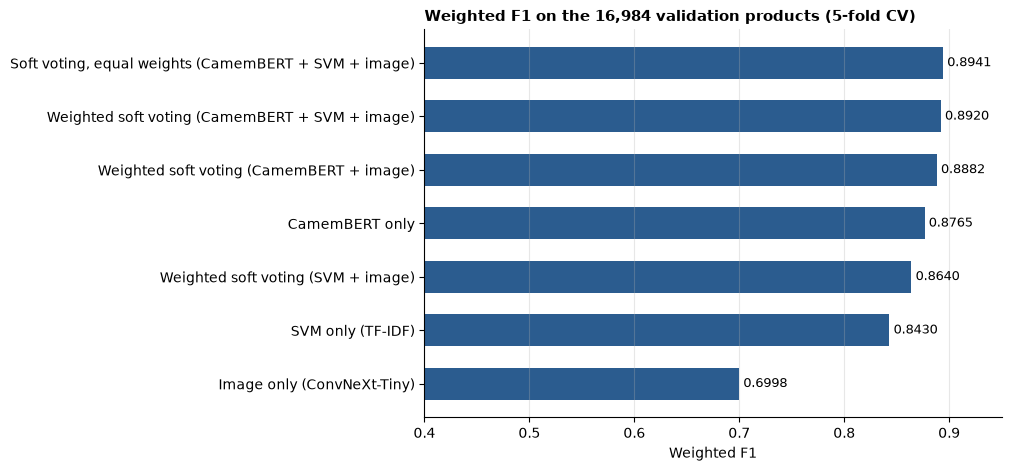

Model,Weighted F1,Macro F1,Errors
"Soft voting, equal weights (CamemBERT + SVM + image)",0.8941,0.8826,1776
Weighted soft voting (CamemBERT + SVM + image),0.8920,0.8797,1813
Weighted soft voting (CamemBERT + image),0.8882,0.8730,1875
CamemBERT only,0.8765,0.8594,2082
Weighted soft voting (SVM + image),0.8640,0.8548,2278
SVM only (TF-IDF),0.8430,0.8326,2656
Image only (ConvNeXt-Tiny),0.6998,0.6752,5043


In [3]:
camembert                = pd.read_csv(CAMEMBERT_PROBS_PATH)
P_camembert              = both[["row_id"]].merge(camembert, on="row_id")[[str(c) for c in classes]].to_numpy()

X_all                    = np.hstack([P_camembert, P_text, P_image])
folds                    = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
steps                    = np.round(np.arange(0, 1.01, 0.1), 1)
pairs                    = [(w, round(1 - w, 1)) for w in steps]
triples                  = [(a, b, round(1 - a - b, 1)) for a in steps for b in steps if a + b <= 1.001]

# Soft voting: the models to average and the weight combinations to try.
# Equal weights has a single option, so nothing is chosen for it.
soft_votes               = {
    "Soft voting, equal weights (CamemBERT + SVM + image)": ([P_camembert, P_text, P_image], [(1 / 3, 1 / 3, 1 / 3)]),
    "Weighted soft voting (SVM + image)"                  : ([P_text, P_image], pairs),
    "Weighted soft voting (CamemBERT + image)"            : ([P_camembert, P_image], pairs),
    "Weighted soft voting (CamemBERT + SVM + image)"      : ([P_camembert, P_text, P_image], triples),
}


def soft_vote(probs, weights, idx):
    return classes[sum(w * P[idx] for w, P in zip(weights, probs)).argmax(axis=1)]


predictions              = {
    "Image only (ConvNeXt-Tiny)"            : classes[P_image.argmax(axis=1)],
    "SVM only (TF-IDF)"                     : classes[P_text.argmax(axis=1)],
    "CamemBERT only"                         : classes[P_camembert.argmax(axis=1)],
    **{name: np.zeros_like(y_true) for name in soft_votes},
}
chosen_weights           = {name: [] for name in soft_votes}

for train_idx, test_idx in folds.split(X_all, y_true):
    for name, (probs, grid) in soft_votes.items():
        fold_scores      = [f1_score(y_true[train_idx], soft_vote(probs, w, train_idx), average="weighted") for w in grid]
        best_w           = grid[int(np.argmax(fold_scores))]
        chosen_weights[name].append(tuple(round(float(w), 2) for w in best_w))
        predictions[name][test_idx] = soft_vote(probs, best_w, test_idx)

for name, chosen in chosen_weights.items():
    if len(soft_votes[name][1]) > 1:
        print(f"{name} — weights chosen in each fold: {chosen}")
results                  = pd.DataFrame({
    "Model":       list(predictions),
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in predictions.values()],
    "Macro F1":    [f1_score(y_true, p, average="macro")    for p in predictions.values()],
    "Errors":      [int((p != y_true).sum()) for p in predictions.values()],
})
results.to_csv(PROJECT_ROOT / "models" / "outputs" / "04_fusion_results.csv", index=False)

fig, ax                  = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
ordered                  = results.sort_values("Weighted F1")
bars                     = ax.barh(ordered["Model"], ordered["Weighted F1"], color="#2b5c8f", height=0.6)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in ordered["Weighted F1"]], padding=3, fontsize=9)
ax.set_xlim(0.4, 0.95)
ax.set_title("Weighted F1 on the 16,984 validation products (5-fold CV)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Weighted F1")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

display(results.sort_values("Weighted F1", ascending=False).style.hide(axis="index").format(precision=4, subset=["Weighted F1", "Macro F1"]))

### Analysis

- Final model: soft voting with equal weights on CamemBERT, SVM and image: 0.8941 weighted F1, 0.8826 macro F1, 1776 errors.
- That is +1.8 points over CamemBERT alone (0.8765) and +5.1 points over the SVM alone (0.8430).
- Nothing is fitted on the validation products, so this score compares directly with the single models.
- Weighted soft voting on the same three models reaches 0.8920 (weights 0.4 CamemBERT, 0.3 SVM, 0.3 image in 4 of 5 folds). Choosing the weights does not help: equal weights are 0.2 points better.
  - The reason is the grid: weights move in steps of 0.1, so 1/3 cannot be chosen. The closest options are 0.4/0.3/0.3 and 0.3/0.4/0.3.
  - Equal weights also score best on the 4/5 part of every fold, so the search would pick them if 1/3 were in the grid. The 0.2-point gap is within noise.
- Weighted soft voting with CamemBERT and image (0.5 each) reaches 0.8882. With SVM and image (0.6 SVM, 0.4 image) it reaches 0.8640.
- The weights are almost the same in every fold, so the choice is stable.


## 4. Per category: equal soft voting vs CamemBERT

In [4]:
best                     = "Soft voting, equal weights (CamemBERT + SVM + image)"
camembert_scores         = compute_per_class_metrics(y_true, predictions["CamemBERT only"], classes)
best_scores              = compute_per_class_metrics(y_true, predictions[best], classes)

per_class                = pd.DataFrame({
    "Code":           classes,
    "Category":       [CATEGORY_NAMES[c] for c in classes],
    "CamemBERT F1":   camembert_scores["f1"],
    "Fusion F1":      best_scores["f1"],
})
per_class["Gain"]        = per_class["Fusion F1"] - per_class["CamemBERT F1"]
per_class.to_csv(PROJECT_ROOT / "models" / "outputs" / "04_fusion_per_class.csv", index=False)
display(per_class.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3))


Code,Category,CamemBERT F1,Fusion F1,Gain
1180,Wargames,0.614,0.720,0.107
10,Used Books,0.689,0.775,0.086
2705,New Books,0.818,0.904,0.086
40,Games,0.795,0.854,0.059
1302,Outdoor Toys,0.810,0.854,0.044
1140,Figurines,0.834,0.874,0.040
2220,Pets,0.890,0.923,0.033
1320,Baby,0.856,0.886,0.029
2462,Used Games,0.821,0.845,0.024
2585,Garden Tools,0.823,0.846,0.023


### Analysis

- Equal soft voting is better than CamemBERT on 22 of the 27 categories.
- 5 categories drop slightly: RC Models (-1.9 points), Baby Socks (-0.6), Board Games (-0.4), Textiles (-0.2) and Toys (-0.1).
- The largest gains are on Wargames (+10.7 points), Used Books (+8.6) and New Books (+8.6).
- Books gain the most from the image: the cover shows if a book is new, used, or a lot of several books.
- Wargames was CamemBERT's weakest category. The SVM catches its rare exact words (*warhammer*, *heroclix*), so combining both fixes it.


## 5. Tried and not kept: Random Forest

A Random Forest can learn from the 81 probabilities (27 classes × 3 models) how to combine them. It must learn from products the three models never saw, and here the only such products are the 16984 validation products. So we train and score it with 5-fold cross-validation on them: it learns on 4/5 and predicts the remaining 1/5.

In [5]:
forest_predictions       = np.zeros_like(y_true)
for train_idx, test_idx in folds.split(X_all, y_true):
    forest               = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    forest_predictions[test_idx] = forest.fit(X_all[train_idx], y_true[train_idx]).predict(X_all[test_idx])

comparison               = pd.DataFrame({
    "Model":       ["Soft voting, equal weights (final)", "Random Forest (not kept)"],
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in (predictions[best], forest_predictions)],
    "Macro F1":    [f1_score(y_true, p, average="macro")    for p in (predictions[best], forest_predictions)],
    "Errors":      [int((p != y_true).sum()) for p in (predictions[best], forest_predictions)],
})
comparison.to_csv(PROJECT_ROOT / "models" / "outputs" / "04_fusion_random_forest.csv", index=False)
display(comparison.style.hide(axis="index").format(precision=4, subset=["Weighted F1", "Macro F1"]))

Model,Weighted F1,Macro F1,Errors
"Soft voting, equal weights (final)",0.8941,0.8826,1776
Random Forest (not kept),0.8988,0.8856,1715


### Analysis

- The Random Forest scores 0.8988 weighted F1 (1715 errors), against 0.8941 for equal soft voting (1776 errors).
- But it learns from the validation products, while the single models and equal soft voting learn nothing from them. Its score is therefore not comparable, and we do not keep it.
- A fair test needs a separate test set: train each base model five times on the training split to get predictions for the Random Forest, and keep the validation products untouched. This is left for later work.
- Gradient Boosting was also tried instead of the Random Forest (appendix notebook). It scored slightly lower and was much slower.

## Conclusion

- Combining models helps: equal soft voting on CamemBERT, SVM and image reaches 0.8941 weighted F1, +1.8 points over CamemBERT alone.
- Choosing the weights does not improve it.
- Final model: equal soft voting. Nothing is fitted on the validation products, so its score compares directly with the single models.
- Each part adds something: CamemBERT reads context, the SVM catches rare specific words, and the image helps on books.
